# ARCADE Stenosis — DeepLabV3+ (ResNet101), 5-fold ensemble, official-protocol reporting

**Goal:** get the best *honest* DeepLabV3+ R101 result on ARCADE, reported with the same metric code as the YOLOv8s-seg notebook, so both models sit in one fair table. Targets from your supervisor: **Dice ≥ 0.65, F1 ≥ 0.55**.

## What is different from the single-model notebook (and why it should help)
| Change | Why |
|---|---|
| **5-fold cross-validation on train+val (1200 images), ensemble of 5 models** | Averaging 5 models is the most reliable +Dice trick on small data; also gives 1200 *out-of-fold* predictions to tune post-processing on (instead of only 200 val images). |
| **EMA of weights, warm-up + cosine LR** | Smoother, better final weights; less noisy than "best epoch of a jumpy curve". |
| **Multi-scale + flip TTA** (chosen on out-of-fold data) | Thin lesions: seeing the image at 1.25× helps the decoder. Picked by OOF Dice, never by test. |
| **Post-processing grid on 1200 OOF images** (threshold, blob size, score cut-off, max lesions) | Same selection idea that took YOLOv8s-seg to 0.48, but with 6× more data to choose from. |
| **Same official metric code as your YOLOv8s-seg notebook** | Your "official ARCADE mean F1" (per-image, matched by Dice) and Dice from the *same* final predictions. |

## Honest rules (so the result is claimable)
1. **The test set (300 images) is touched exactly once**, at the very end, after every choice is frozen. Nothing is tuned on it.
2. Six operating points are reported, **clearly labelled**; you may claim a number only together with its label.
3. The notebook prints a **claim gate**: it tells you which of Dice ≥ 0.65 / F1 ≥ 0.55 were actually reached (point value *and* 95 % CI lower bound). If not reached, it says so; do not write the target in the thesis.
4. `top1` (force at least one lesion per image) works on ARCADE because almost every image has a lesion. It would produce false alarms on healthy frames (see your CADICA result: 14.6 % specificity). So rows with and without it are both shown.

## How to run
1. **First run `SMOKE_TEST = True`** (≈ 5-10 min). It trains 1 epoch on ~120 images just to prove every cell works.
2. Then set `SMOKE_TEST = False` and run all. Time on a free T4: roughly **2-3 h** for `MODE="best"` (5 folds × 40 epochs). Keep the browser tab open.
3. Nothing to upload. ARCADE downloads itself. Nothing is written to Drive.

In [1]:
!pip install -q segmentation-models-pytorch pycocotools scikit-image kagglehub albumentations scikit-learn scipy
print("Installs complete.")

Installs complete.


In [2]:
import os, json, math, copy, random, itertools, shutil, time, warnings
from pathlib import Path
from collections import Counter

import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm

import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torch.amp import autocast, GradScaler
import albumentations as A
import segmentation_models_pytorch as smp
from sklearn.model_selection import StratifiedKFold

warnings.filterwarnings("ignore")
SEED = 42
def seed_everything(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
seed_everything(SEED)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_CUDA = DEVICE.type == "cuda"
torch.backends.cudnn.benchmark = True
print("Torch", torch.__version__, "| smp", smp.__version__, "|", torch.cuda.get_device_name(0) if USE_CUDA else "NO GPU")

Torch 2.14.1+cu130 | smp 0.6.0 | Tesla T4


In [3]:
# ============================================================
# CONFIG
# ============================================================
SMOKE_TEST = False         # True = 5-10 min plumbing check (1 epoch, ~120 images). Set False for the real run.
MODE = "best"              # "best": 5 folds x 40 epochs | "fast": 5 folds x 25 epochs (quicker, slightly weaker)
ARCHS = ["dl3_r101"]       # supervisor's model. Optional extra for the ensemble: "unet_r101", "fpn_r101" (+~2 h each)

PRESETS = {"best": dict(N_FOLDS=5, EPOCHS=40), "fast": dict(N_FOLDS=5, EPOCHS=25)}
N_FOLDS, EPOCHS = PRESETS[MODE]["N_FOLDS"], PRESETS[MODE]["EPOCHS"]
BATCH_SIZE, WARMUP_EPOCHS, EMA_DECAY = 8, 2, 0.997
LR_ENCODER, LR_DECODER = 1e-4, 1e-3
POS_WEIGHT, TVERSKY_ALPHA, TVERSKY_BETA = 3.0, 0.5, 0.5
IMG_SIZE, STENOSIS_CATEGORY_ID = 512, 26
N_BOOT = 1000

if SMOKE_TEST:
    N_FOLDS, EPOCHS, N_BOOT = 2, 1, 100
    SMOKE_POOL, SMOKE_TEST_N = 120, 60

RUN_DIR = Path("/content/run"); RUN_DIR.mkdir(parents=True, exist_ok=True)
OUT_DIR = Path("/content/outputs"); OUT_DIR.mkdir(parents=True, exist_ok=True)
print(f"SMOKE_TEST={SMOKE_TEST} | MODE={MODE} | folds={N_FOLDS} | epochs={EPOCHS} | archs={ARCHS}")

SMOKE_TEST=False | MODE=best | folds=5 | epochs=40 | archs=['dl3_r101']


In [4]:
import kagglehub
download_path = Path(kagglehub.dataset_download("nirmalgaud/arcade-dataset"))
cands = [c for c in download_path.rglob("train.json") if "stenosis" in str(c).lower()]
if not cands: raise FileNotFoundError("No 'stenosis' train.json found (wrong ARCADE sub-task folder).")
DATASET_ROOT = cands[0].parent.parent.parent
for s in ["train", "val", "test"]:
    assert (DATASET_ROOT / s / "annotations" / f"{s}.json").exists() and (DATASET_ROOT / s / "images").exists()
print("ARCADE root:", DATASET_ROOT)

100%|██████████| 431M/431M [00:22<00:00, 20.2MB/s]

Extracting files...


ARCADE root: /root/.cache/kagglehub/datasets/nirmalgaud/arcade-dataset/versions/1/arcade/stenosis


## Official-protocol metric code (copied from your YOLOv8s-seg notebook so numbers are directly comparable)
Instance = one lesion mask. **Official ARCADE mean F1** (`P1`): per image, predicted and GT lesions are matched greedily by Dice; a matched pair scores its Dice; every unmatched prediction or GT lesion scores 0; averaged per image, then over images.

In [5]:
# ============================================================
# Instances + official metrics (identical logic to the YOLOv8s-seg notebook; adds per-image Dice output)
# ============================================================
class Inst:
    """One instance mask, cropped to its bounding box."""
    __slots__ = ("y0", "x0", "m", "area", "score", "extra")
    def __init__(self, y0, x0, m, score=1.0, extra=None):
        self.y0, self.x0, self.m = int(y0), int(x0), m
        self.area = int(m.sum()); self.score, self.extra = float(score), extra
    @property
    def y1(self): return self.y0 + self.m.shape[0]
    @property
    def x1(self): return self.x0 + self.m.shape[1]

def inst_from_full(full_bool, score=1.0):
    ys, xs = np.nonzero(full_bool)
    if len(ys) == 0: return None
    y0, y1, x0, x1 = ys.min(), ys.max() + 1, xs.min(), xs.max() + 1
    return Inst(y0, x0, full_bool[y0:y1, x0:x1].copy(), score)

def inst_inter(a, b):
    y0, y1 = max(a.y0, b.y0), min(a.y1, b.y1); x0, x1 = max(a.x0, b.x0), min(a.x1, b.x1)
    if y0 >= y1 or x0 >= x1: return 0
    return int(np.count_nonzero(a.m[y0 - a.y0:y1 - a.y0, x0 - a.x0:x1 - a.x0] & b.m[y0 - b.y0:y1 - b.y0, x0 - b.x0:x1 - b.x0]))

def inst_dice(a, b):
    s = a.area + b.area
    return 0.0 if s == 0 else 2.0 * inst_inter(a, b) / s

def inst_iou(a, b):
    i = inst_inter(a, b); u = a.area + b.area - i
    return 0.0 if u == 0 else i / u

def paint(insts, shape):
    canvas = np.zeros(shape, bool)
    for i in insts: canvas[i.y0:i.y1, i.x0:i.x1] |= i.m
    return canvas

def inst_greedy_match(preds, gts, criterion="dice"):
    fn = inst_dice if criterion == "dice" else inst_iou
    pairs = []
    for i, p in enumerate(preds):
        for j, g in enumerate(gts):
            s = fn(p, g)
            if s > 0: pairs.append((s, i, j))
    pairs.sort(key=lambda t: -t[0])
    up, ug, out = set(range(len(preds))), set(range(len(gts))), []
    for s, i, j in pairs:
        if i in up and j in ug: out.append((i, j, s)); up.discard(i); ug.discard(j)
    return out, len(up), len(ug)

def p1_image(preds, gts):
    if not preds and not gts: return 1.0
    pairs, n_up, n_ug = inst_greedy_match(preds, gts, "dice")
    return float(np.mean([s for _, _, s in pairs] + [0.0] * (n_up + n_ug)))

def full_metrics(preds_by_img, items):
    p1, p1s, dimg, iimg = [], [], [], []
    TP = FP = FN = pTP = pFP = pFN = 0
    for k, it in enumerate(items):
        preds, gts = preds_by_img[k], it["gts"]
        p1.append(p1_image(preds, gts))
        pairs, n_up, n_ug = inst_greedy_match(preds, gts, "iou")
        sc, tp = [], 0
        for i, j, s in pairs:
            if s >= 0.5: sc.append(inst_dice(preds[i], gts[j])); tp += 1
            else: sc += [0.0, 0.0]
        sc += [0.0] * (n_up + n_ug)
        p1s.append(float(np.mean(sc)) if sc else 1.0)
        TP += tp; FP += len(preds) - tp; FN += len(gts) - tp
        pr, gt = paint(preds, it["shape"]), paint(gts, it["shape"])
        a, b, c = np.count_nonzero(pr & gt), np.count_nonzero(pr & ~gt), np.count_nonzero(~pr & gt)
        pTP += a; pFP += b; pFN += c
        dimg.append(1.0 if a + b + c == 0 else 2 * a / (2 * a + b + c))
        iimg.append(1.0 if a + b + c == 0 else a / (a + b + c))
    P, R = TP / max(TP + FP, 1e-9), TP / max(TP + FN, 1e-9)
    return {"P1": float(np.mean(p1)), "P1_strict": float(np.mean(p1s)),
            "F1": 2 * P * R / max(P + R, 1e-9), "Precision": P, "Recall": R, "TP": TP, "FP": FP, "FN": FN,
            "Dice": 2 * pTP / max(2 * pTP + pFP + pFN, 1e-9), "IoU": pTP / max(pTP + pFP + pFN, 1e-9),
            "Dice_img": float(np.mean(dimg)), "Dice_img_std": float(np.std(dimg)),
            "IoU_img": float(np.mean(iimg)), "pred_per_img": (TP + FP) / len(items),
            "per_image_P1": np.array(p1), "per_image_Dice": np.array(dimg)}

def mask_map(ranked_by_img, items, thrs=np.arange(0.50, 0.96, 0.05)):
    """COCO-style mask AP (101-point). Returns (AP50, AP50-95)."""
    ious = [np.array([[inst_iou(p, g) for g in it["gts"]] for p in ranked_by_img[k]], np.float32)
            .reshape(len(ranked_by_img[k]), len(it["gts"])) for k, it in enumerate(items)]
    n_gt = sum(len(it["gts"]) for it in items)
    order = sorted(((p.score, k, i) for k, ps in enumerate(ranked_by_img) for i, p in enumerate(ps)), key=lambda d: -d[0])
    aps = []
    for thr in thrs:
        used = [np.zeros(len(it["gts"]), bool) for it in items]; tp = np.zeros(len(order))
        for n, (_, k, i) in enumerate(order):
            if ious[k].shape[1] == 0: continue
            cand = np.where(~used[k], ious[k][i], -1.0); j = int(cand.argmax())
            if cand[j] >= thr: used[k][j] = True; tp[n] = 1
        ctp, cfp = np.cumsum(tp), np.cumsum(1 - tp); rec = ctp / max(n_gt, 1)
        prec = np.maximum.accumulate((ctp / np.maximum(ctp + cfp, 1e-9))[::-1])[::-1] if len(order) else np.zeros(0)
        aps.append(float(np.mean([prec[rec >= r].max() if np.any(rec >= r) else 0.0 for r in np.linspace(0, 1, 101)])))
    return aps[0], float(np.mean(aps))

_g = [Inst(0, 0, np.ones((5, 5), bool))]
print("self-check official F1: perfect =", p1_image(_g, _g), "| one extra false positive =", round(p1_image(_g + [Inst(9, 9, np.ones((3, 3), bool))], _g), 3))

self-check official F1: perfect = 1.0 | one extra false positive = 0.5


In [6]:
# ============================================================
# Load ARCADE: arrays (gray 512x512) + GT instances from the COCO polygons (native resolution)
# ============================================================
def polys_to_mask(segs, h, w):
    full = np.zeros((h, w), np.uint8)
    for poly in segs or []:
        if isinstance(poly, list) and len(poly) >= 6:
            cv2.fillPoly(full, [np.round(np.array(poly, np.float32).reshape(-1, 2)).astype(np.int32)], 1)
    return full

def load_split(split):
    coco = json.load(open(DATASET_ROOT / split / "annotations" / f"{split}.json"))
    anns = {}
    for a in coco["annotations"]:
        if a["category_id"] == STENOSIS_CATEGORY_ID: anns.setdefault(a["image_id"], []).append(a)
    imgs, masks, items = [], [], []
    for im in tqdm(sorted(coco["images"], key=lambda d: d["id"]), desc=f"ARCADE {split}"):
        g = cv2.imread(str(DATASET_ROOT / split / "images" / im["file_name"]), cv2.IMREAD_GRAYSCALE)
        assert g.shape == (IMG_SIZE, IMG_SIZE), f"{im['file_name']} is {g.shape}, expected 512x512 (ARCADE native)"
        h, w = g.shape
        gts, union = [], np.zeros((h, w), np.uint8)
        for a in anns.get(im["id"], []):
            m = polys_to_mask(a.get("segmentation"), h, w); union |= m
            gi = inst_from_full(m.astype(bool))
            if gi is not None: gts.append(gi)
        imgs.append(g); masks.append(union); items.append({"file": im["file_name"], "shape": (h, w), "gts": gts})
    return np.stack(imgs), np.stack(masks), items

ARC = {s: load_split(s) for s in ["train", "val", "test"]}
for s, (a, m, it) in ARC.items():
    n = sum(len(i["gts"]) for i in it)
    print(f"{s:5s}: {len(a)} images | {n} lesions | {n / len(a):.2f} per image")

# pool = train + val (used for cross-validation); test is kept untouched until the very end
POOL_IMGS = np.concatenate([ARC["train"][0], ARC["val"][0]])
POOL_MASKS = np.concatenate([ARC["train"][1], ARC["val"][1]])
POOL_ITEMS = ARC["train"][2] + ARC["val"][2]
TEST_IMGS, TEST_MASKS, TEST_ITEMS = ARC["test"]
if SMOKE_TEST:
    rs = np.random.default_rng(0)
    pi = np.sort(rs.choice(len(POOL_IMGS), SMOKE_POOL, replace=False)); ti = np.sort(rs.choice(len(TEST_IMGS), SMOKE_TEST_N, replace=False))
    POOL_IMGS, POOL_MASKS, POOL_ITEMS = POOL_IMGS[pi], POOL_MASKS[pi], [POOL_ITEMS[i] for i in pi]
    TEST_IMGS, TEST_MASKS, TEST_ITEMS = TEST_IMGS[ti], TEST_MASKS[ti], [TEST_ITEMS[i] for i in ti]
N_POOL = len(POOL_IMGS)
MIN_AREA_REF = int(np.percentile([g.area for it in POOL_ITEMS for g in it["gts"]], 5))
print(f"pool: {N_POOL} images | test: {len(TEST_IMGS)} images | 5th-percentile lesion area = {MIN_AREA_REF}px")

ARCADE train:   0%|          | 0/1000 [00:00<?, ?it/s]

ARCADE val:   0%|          | 0/200 [00:00<?, ?it/s]

ARCADE test:   0%|          | 0/300 [00:00<?, ?it/s]

train: 1000 images | 1625 lesions | 1.62 per image
val  : 200 images | 406 lesions | 2.03 per image
test : 300 images | 386 lesions | 1.29 per image
pool: 1200 images | test: 300 images | 5th-percentile lesion area = 331px


## Post-processing search (numpy only) on out-of-fold predictions
For each image we keep predicted lesions (connected blobs) that pass: probability **threshold**, **min blob size**, **score cut-off τ**, **relative cut-off** (vs the best blob), **max lesions k**, optional **top1** (force ≥ 1 lesion). The score of a blob is its mean probability. All choices are made on the 1200 out-of-fold images, never on test.

In [7]:
# ============================================================
# Candidate lesions per image + fast evaluation of one post-processing config
# ============================================================
def build_cands(probs, gtu, items, thr, min_area):
    """probs: (N,H,W) float; gtu: (N,H,W) bool GT union. One dict per image with blobs sorted by score."""
    out = []
    for k in range(len(probs)):
        p = probs[k].astype(np.float32)
        n, lab, stats, _ = cv2.connectedComponentsWithStats((p > thr).astype(np.uint8), connectivity=8)
        preds = []
        for i in range(1, n):
            x, y, w, h, a = stats[i]
            if a < min_area: continue
            m = lab[y:y + h, x:x + w] == i
            preds.append(Inst(y, x, m, score=float(p[y:y + h, x:x + w][m].mean())))
        preds.sort(key=lambda t: -t.score)
        gts = items[k]["gts"]
        D = np.zeros((len(preds), len(gts)), np.float32)
        for i, pr in enumerate(preds):
            for j, g in enumerate(gts): D[i, j] = inst_dice(pr, g)
        inter = np.array([np.count_nonzero(pr.m & gtu[k][pr.y0:pr.y1, pr.x0:pr.x1]) for pr in preds], np.int64)
        out.append(dict(preds=preds, scores=np.array([pr.score for pr in preds]), area=np.array([pr.area for pr in preds], np.int64),
                        inter=inter, D=D, gt_area=int(gtu[k].sum()), ngt=len(gts)))
    return out

def keep_idx(sc, tau, rel, max_k, top1):
    n = len(sc)
    keep = [i for i in range(n) if sc[i] >= tau and sc[i] >= rel * sc[0]][:max_k]
    if not keep and top1 and n: keep = [0]
    return keep

def p1_from_D(Dsub, n_gt):
    n_pred = Dsub.shape[0]
    if n_pred == 0 and n_gt == 0: return 1.0
    scores, matched_p, matched_g = [], set(), set()
    if n_pred and n_gt:
        ii, jj = np.nonzero(Dsub > 0)
        for o in np.argsort(-Dsub[ii, jj], kind="stable"):
            i, j = int(ii[o]), int(jj[o])
            if i not in matched_p and j not in matched_g:
                scores.append(float(Dsub[i, j])); matched_p.add(i); matched_g.add(j)
    scores += [0.0] * ((n_pred - len(matched_p)) + (n_gt - len(matched_g)))
    return float(np.mean(scores))

def eval_cfg(C, tau, rel, max_k, top1):
    d_sum = p_sum = 0.0
    for c in C:
        keep = keep_idx(c["scores"], tau, rel, max_k, top1)
        P = int(c["area"][keep].sum()) if keep else 0; I = int(c["inter"][keep].sum()) if keep else 0
        d_sum += 1.0 if P + c["gt_area"] == 0 else 2.0 * I / (P + c["gt_area"])
        p_sum += p1_from_D(c["D"][keep] if keep else np.zeros((0, c["ngt"]), np.float32), c["ngt"])
    return d_sum / len(C), p_sum / len(C)

def select_insts(c, cfg):
    return [c["preds"][i] for i in keep_idx(c["scores"], cfg["tau"], cfg["rel"], cfg["max_k"], cfg["top1"])]

GRID = dict(thr=[0.30, 0.35, 0.40, 0.45, 0.50, 0.55], min_area=sorted({150, MIN_AREA_REF}),
            tau=[0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8], rel=[0.0, 0.5, 0.75], max_k=[1, 2, 3, 99], top1=[True, False])

def search_postproc(probs, gtu, items, grid=GRID, verbose=True):
    rows = []
    for thr, ma in itertools.product(grid["thr"], grid["min_area"]):
        C = build_cands(probs, gtu, items, thr, ma)
        for tau, rel, mk, t1 in itertools.product(grid["tau"], grid["rel"], grid["max_k"], grid["top1"]):
            d, p = eval_cfg(C, tau, rel, mk, t1)
            rows.append(dict(thr=thr, min_area=ma, tau=tau, rel=rel, max_k=mk, top1=t1, dice_img=d, p1=p))
        if verbose: print(f"  thr={thr:.2f} min_area={ma}: done", end="\r")
    return pd.DataFrame(rows)

def pick_ops(df):
    """Six labelled operating points: objective x (ARCADE protocol with top1 allowed | deployable without top1)."""
    ops = {}
    for tag, sub in [("ARCADE", df), ("DEPLOY", df[~df.top1])]:
        for obj, key in [("maxDice", df.dice_img), ("maxF1", df.p1), ("balanced", (df.dice_img + df.p1) / 2)]:
            s = (key.loc[sub.index]); r = df.loc[s.idxmax()]
            ops[f"{obj}-{tag}"] = dict(thr=float(r.thr), min_area=int(r.min_area), tau=float(r.tau), rel=float(r.rel),
                                       max_k=int(r.max_k), top1=bool(r.top1), oof_dice=float(r.dice_img), oof_p1=float(r.p1))
    return ops
print("post-processing search ready; grid size per (thr,min_area):",
      len(GRID["tau"]) * len(GRID["rel"]) * len(GRID["max_k"]) * len(GRID["top1"]), "| (thr,min_area) sets:", len(GRID["thr"]) * len(GRID["min_area"]))

post-processing search ready; grid size per (thr,min_area): 168 | (thr,min_area) sets: 12


## Model, loss, EMA, training (one fold)
DeepLabV3+ with a pretrained ResNet101 encoder (ImageNet normalisation inside the model), two learning rates (encoder 1e-4, decoder 1e-3), BCE + Tversky loss, warm-up + cosine schedule, EMA weights. The EMA model is the one that is validated and saved.

In [8]:
class NormalizedSegModel(nn.Module):
    def __init__(self, net):
        super().__init__(); self.net = net
        self.register_buffer("mean", torch.tensor([0.485, 0.456, 0.406]).view(1, 3, 1, 1))
        self.register_buffer("std",  torch.tensor([0.229, 0.224, 0.225]).view(1, 3, 1, 1))
    def forward(self, x): return self.net((x - self.mean) / self.std)

def build_net(arch, encoder_weights="imagenet"):
    kw = dict(encoder_name="resnet101", encoder_weights=encoder_weights, in_channels=3, classes=1)
    if arch == "dl3_r101":   net = smp.DeepLabV3Plus(**kw)
    elif arch == "unet_r101": net = smp.Unet(decoder_attention_type="scse", **kw)
    elif arch == "fpn_r101":  net = smp.FPN(**kw)
    else: raise ValueError(arch)
    return NormalizedSegModel(net)

def tversky_loss(logits, targets, alpha=TVERSKY_ALPHA, beta=TVERSKY_BETA, eps=1e-6):
    p = torch.sigmoid(logits).view(logits.size(0), -1); t = targets.view(targets.size(0), -1)
    TP = (p * t).sum(1); FP = (p * (1 - t)).sum(1); FN = ((1 - p) * t).sum(1)
    return 1 - ((TP + eps) / (TP + alpha * FP + beta * FN + eps)).mean()

class SegLoss(nn.Module):
    def __init__(self):
        super().__init__(); self.bce = nn.BCEWithLogitsLoss(pos_weight=torch.tensor(float(POS_WEIGHT)))
    def forward(self, lo, t): return 0.5 * self.bce(lo, t) + 0.5 * tversky_loss(lo, t)

class ArrDS(Dataset):
    def __init__(self, imgs, masks, tf=None): self.imgs, self.masks, self.tf = imgs, masks, tf
    def __len__(self): return len(self.imgs)
    def __getitem__(self, i):
        img = np.repeat(self.imgs[i][..., None], 3, 2); m = self.masks[i].astype(np.float32)
        if self.tf is not None:
            o = self.tf(image=img, mask=m); img, m = o["image"], o["mask"]
        return torch.from_numpy(img.astype(np.float32) / 255.0).permute(2, 0, 1), torch.from_numpy(m).unsqueeze(0)

class EMA:
    def __init__(self, model, decay):
        self.m = copy.deepcopy(model).eval(); self.decay = decay
        for p in self.m.parameters(): p.requires_grad_(False)
    @torch.no_grad()
    def update(self, model, step):
        d = min(self.decay, (1 + step) / (10 + step)); msd = model.state_dict()
        for k, v in self.m.state_dict().items():
            if v.dtype.is_floating_point: v.mul_(d).add_(msd[k].detach(), alpha=1 - d)
            else: v.copy_(msd[k])

def batch_dice(logits, targets, thr=0.5, eps=1e-6):
    p = (torch.sigmoid(logits) > thr).float().view(logits.size(0), -1); t = targets.view(targets.size(0), -1)
    return ((2 * (p * t).sum(1) + eps) / (p.sum(1) + t.sum(1) + eps)).mean().item()

def train_fold(arch, fold, tr_idx, va_idx):
    seed_everything(SEED + 100 * ARCHS.index(arch) + fold)
    tf = A.Compose([A.HorizontalFlip(p=0.5),
                    A.Affine(rotate=(-10, 10), translate_percent=(0.0, 0.10), scale=(0.85, 1.15), shear=(-2, 2), p=0.7),
                    A.RandomBrightnessContrast(brightness_limit=0.15, contrast_limit=0.15, p=0.5),
                    A.RandomGamma(p=0.3), A.GaussNoise(p=0.2)])
    tl = DataLoader(ArrDS(POOL_IMGS[tr_idx], POOL_MASKS[tr_idx], tf), batch_size=BATCH_SIZE, shuffle=True, num_workers=2,
                    drop_last=True, pin_memory=USE_CUDA, persistent_workers=True)
    vl = DataLoader(ArrDS(POOL_IMGS[va_idx], POOL_MASKS[va_idx]), batch_size=BATCH_SIZE, shuffle=False, num_workers=0)
    model = build_net(arch, "imagenet").to(DEVICE); crit = SegLoss().to(DEVICE); ema = EMA(model, EMA_DECAY)
    enc = list(model.net.encoder.parameters()); ids = {id(p) for p in enc}; dec = [p for p in model.parameters() if id(p) not in ids]
    opt = torch.optim.AdamW([{"params": enc, "lr": LR_ENCODER}, {"params": dec, "lr": LR_DECODER}], weight_decay=1e-4)
    total, warm = EPOCHS * len(tl), max(1, WARMUP_EPOCHS * len(tl))
    sched = torch.optim.lr_scheduler.LambdaLR(opt, lambda s: min(1.0, (s + 1) / warm) * max(0.01, 0.5 * (1 + math.cos(math.pi * min(s, total) / total))))
    scaler = GradScaler("cuda", enabled=USE_CUDA)
    best, best_state, step, t0 = -1.0, None, 0, time.time()
    for ep in range(1, EPOCHS + 1):
        model.train(); tot = 0.0
        for x, y in tl:
            x, y = x.to(DEVICE, non_blocking=True), y.to(DEVICE, non_blocking=True); opt.zero_grad(set_to_none=True)
            with autocast("cuda", enabled=USE_CUDA): lo = model(x)
            loss = crit(lo.float(), y); scaler.scale(loss).backward(); scaler.step(opt); scaler.update(); sched.step()
            ema.update(model, step); step += 1; tot += loss.item() * x.size(0)
        ds, n = 0.0, 0
        with torch.no_grad():
            for x, y in vl:
                x, y = x.to(DEVICE), y.to(DEVICE)
                with autocast("cuda", enabled=USE_CUDA): lo = ema.m(x)
                ds += batch_dice(lo.float(), y) * x.size(0); n += x.size(0)
        vd = ds / n
        if vd > best: best = vd; best_state = {k: v.detach().cpu().clone() for k, v in ema.m.state_dict().items()}
        el = time.time() - t0
        print(f"[{arch} f{fold}] ep {ep:2d}/{EPOCHS} loss {tot / (len(tl) * BATCH_SIZE):.4f} | val Dice (EMA) {vd:.4f} | best {best:.4f} | {el:.0f}s (~{el / ep * (EPOCHS - ep):.0f}s left in this fold)")
    del tl, vl, model, ema, opt; torch.cuda.empty_cache()
    return best_state, best

MODES = ["none", "flip", "ms"]

@torch.no_grad()
def tta_probs(model, imgs, bs=8):
    """Returns {'none': single pass, 'flip': +hflip, 'ms': 2 scales (1.0, 1.25) x hflip}, each (N,512,512) float16."""
    model.eval(); out = {m: [] for m in MODES}
    for s in range(0, len(imgs), bs):
        x = torch.from_numpy(imgs[s:s + bs]).float().div(255).unsqueeze(1).repeat(1, 3, 1, 1).to(DEVICE); ps = []
        for sc in (1.0, 1.25):
            xs = x if sc == 1.0 else F.interpolate(x, scale_factor=sc, mode="bilinear", align_corners=False)
            with autocast("cuda", enabled=USE_CUDA):
                p = torch.sigmoid(model(xs).float())
                pf = torch.flip(torch.sigmoid(model(torch.flip(xs, dims=[3])).float()), dims=[3])
            if sc != 1.0:
                p = F.interpolate(p, size=x.shape[-2:], mode="bilinear", align_corners=False)
                pf = F.interpolate(pf, size=x.shape[-2:], mode="bilinear", align_corners=False)
            ps.append((p, pf))
        res = {"none": ps[0][0], "flip": (ps[0][0] + ps[0][1]) / 2, "ms": (ps[0][0] + ps[0][1] + ps[1][0] + ps[1][1]) / 4}
        for m in MODES: out[m].append(res[m][:, 0].cpu().numpy().astype(np.float16))
    return {m: np.concatenate(v) for m, v in out.items()}
print("training / TTA code ready")

training / TTA code ready


## Cross-validation training (5 folds) + out-of-fold predictions
Each fold trains on 80 % of train+val and predicts the other 20 %. After all folds every one of the 1200 images has one **out-of-fold** prediction, made by a model that never saw it. Those predictions are what the post-processing is tuned on.

In [9]:
y_strat = np.array([min(len(it["gts"]), 3) for it in POOL_ITEMS])
FOLDS = list(StratifiedKFold(n_splits=N_FOLDS, shuffle=True, random_state=SEED).split(np.zeros(N_POOL), y_strat))
OOF = {m: np.zeros((N_POOL, IMG_SIZE, IMG_SIZE), np.float16) for m in MODES}
FOLD_LOG, T_ALL = [], time.time()
for arch in ARCHS:
    for fold, (tr, va) in enumerate(FOLDS):
        ck = RUN_DIR / f"{arch}_f{fold}.pt"
        if ck.exists():
            print(f"[{arch} f{fold}] checkpoint found, skipping training"); state = torch.load(ck, map_location="cpu"); bd = float("nan")
        else:
            state, bd = train_fold(arch, fold, tr, va); torch.save(state, ck)
        net = build_net(arch, None).to(DEVICE); net.load_state_dict(state); net.eval()
        p = tta_probs(net, POOL_IMGS[va]); n_prev = ARCHS.index(arch)
        for m in MODES: OOF[m][va] = ((OOF[m][va].astype(np.float32) * n_prev + p[m].astype(np.float32)) / (n_prev + 1)).astype(np.float16)
        FOLD_LOG.append(dict(arch=arch, fold=fold, n_train=len(tr), n_val=len(va), best_val_dice=bd))
        del net, state; torch.cuda.empty_cache()
        print(f"=== finished {arch} fold {fold + 1}/{N_FOLDS} | total elapsed {(time.time() - T_ALL) / 60:.1f} min ===")
print(pd.DataFrame(FOLD_LOG).round(4).to_string(index=False))

config.json:   0%|          | 0.00/156 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  179MB            

model.safetensors: downloading bytes:           |  0.00B            

[dl3_r101 f0] ep  1/40 loss 0.6905 | val Dice (EMA) 0.2095 | best 0.2095 | 61s (~2374s left in this fold)
[dl3_r101 f0] ep  2/40 loss 0.4712 | val Dice (EMA) 0.3850 | best 0.3850 | 108s (~2047s left in this fold)
[dl3_r101 f0] ep  3/40 loss 0.3803 | val Dice (EMA) 0.4595 | best 0.4595 | 155s (~1908s left in this fold)
[dl3_r101 f0] ep  4/40 loss 0.3457 | val Dice (EMA) 0.5036 | best 0.5036 | 201s (~1811s left in this fold)
[dl3_r101 f0] ep  5/40 loss 0.3265 | val Dice (EMA) 0.5128 | best 0.5128 | 248s (~1734s left in this fold)
[dl3_r101 f0] ep  6/40 loss 0.3059 | val Dice (EMA) 0.5338 | best 0.5338 | 294s (~1668s left in this fold)
[dl3_r101 f0] ep  7/40 loss 0.2924 | val Dice (EMA) 0.5441 | best 0.5441 | 341s (~1607s left in this fold)
[dl3_r101 f0] ep  8/40 loss 0.2831 | val Dice (EMA) 0.5487 | best 0.5487 | 388s (~1551s left in this fold)
[dl3_r101 f0] ep  9/40 loss 0.2844 | val Dice (EMA) 0.5522 | best 0.5522 | 435s (~1497s left in this fold)
[dl3_r101 f0] ep 10/40 loss 0.2715 | v

In [10]:
# ---- choose the TTA mode on OUT-OF-FOLD data (never on test) ----
GTU_POOL = POOL_MASKS > 0
def mean_img_dice(probs, thr):
    d = []
    for s in range(0, N_POOL, 100):
        pr = probs[s:s + 100] > thr; gt = GTU_POOL[s:s + 100]
        inter = (pr & gt).sum((1, 2)); den = pr.sum((1, 2)) + gt.sum((1, 2))
        d.append(np.where(den == 0, 1.0, 2 * inter / np.maximum(den, 1)))
    return float(np.concatenate(d).mean())

rows = [{"TTA mode": m, **{f"Dice@{t}": mean_img_dice(OOF[m], t) for t in (0.35, 0.40, 0.45, 0.50)}} for m in MODES]
tta_tab = pd.DataFrame(rows); tta_tab["best"] = tta_tab[[c for c in tta_tab.columns if c.startswith("Dice@")]].max(1)
print("=== SS-1: out-of-fold per-image Dice (no post-processing), by TTA mode ===")
print(tta_tab.round(4).to_string(index=False))
CHOSEN_MODE = tta_tab.loc[tta_tab["best"].idxmax(), "TTA mode"]
print("chosen TTA mode (by OOF):", CHOSEN_MODE)

=== SS-1: out-of-fold per-image Dice (no post-processing), by TTA mode ===
TTA mode  Dice@0.35  Dice@0.4  Dice@0.45  Dice@0.5   best
    none     0.5801    0.5807     0.5819    0.5820 0.5820
    flip     0.5860    0.5880     0.5893    0.5884 0.5893
      ms     0.5881    0.5903     0.5916    0.5926 0.5926
chosen TTA mode (by OOF): ms


In [11]:
# ---- post-processing search on the out-of-fold predictions ----
t0 = time.time()
DF_OOF = search_postproc(OOF[CHOSEN_MODE], GTU_POOL, POOL_ITEMS)
OPS = pick_ops(DF_OOF)
print(f"\nsearched {len(DF_OOF)} configs in {time.time() - t0:.0f}s")
ops_tab = pd.DataFrame(OPS).T
print("=== SS-2: six operating points chosen on OUT-OF-FOLD data (these numbers are OOF, not test) ===")
print(ops_tab.round(4).to_string())
json.dump({"tta_mode": CHOSEN_MODE, "ops": OPS, "archs": ARCHS, "folds": N_FOLDS, "epochs": EPOCHS}, open(OUT_DIR / "frozen_choices.json", "w"), indent=2)
print("\nFROZEN. Everything above used only train+val. The test set is evaluated next, once.")

  thr=0.55 min_area=331: done
searched 2016 configs in 152s
=== SS-2: six operating points chosen on OUT-OF-FOLD data (these numbers are OOF, not test) ===
                  thr min_area  tau   rel max_k   top1  oof_dice    oof_p1
maxDice-ARCADE   0.35      150  0.2  0.75     3   True  0.595918  0.462198
maxF1-ARCADE     0.45      150  0.7   0.0    99   True  0.591735  0.467506
balanced-ARCADE   0.4      150  0.6  0.75    99   True  0.594939  0.466783
maxDice-DEPLOY   0.35      150  0.2  0.75     3  False  0.595918  0.462198
maxF1-DEPLOY     0.45      331  0.5  0.75     3  False  0.593728  0.465027
balanced-DEPLOY   0.4      150  0.2  0.75    99  False  0.595701  0.464294

FROZEN. Everything above used only train+val. The test set is evaluated next, once.


In [12]:
# ============================================================
# TEST SET - touched here for the first and only time
# ============================================================
GTU_TEST = TEST_MASKS > 0
TEST_FOLD_PROBS, ens_sum = [], np.zeros(TEST_IMGS.shape, np.float32)
for arch in ARCHS:
    for fold in range(N_FOLDS):
        net = build_net(arch, None).to(DEVICE); net.load_state_dict(torch.load(RUN_DIR / f"{arch}_f{fold}.pt", map_location="cpu")); net.eval()
        p = tta_probs(net, TEST_IMGS)[CHOSEN_MODE]; TEST_FOLD_PROBS.append(p); ens_sum += p.astype(np.float32)
        del net; torch.cuda.empty_cache(); print(f"test inference: {arch} fold {fold + 1}/{N_FOLDS}", end="\r")
ENS = (ens_sum / len(TEST_FOLD_PROBS)).astype(np.float16)

def eval_op(probs, cfg):
    C = build_cands(probs, GTU_TEST, TEST_ITEMS, cfg["thr"], cfg["min_area"])
    fm = full_metrics([select_insts(c, cfg) for c in C], TEST_ITEMS)
    return fm, C

RES, rows = {}, []
for name, cfg in OPS.items():
    fm, C = eval_op(ENS, cfg)
    ap50, ap5095 = mask_map([c["preds"] for c in C], TEST_ITEMS)
    rng, n = np.random.default_rng(0), len(TEST_ITEMS); bd, bp = [], []
    for _ in range(N_BOOT):
        idx = rng.integers(0, n, n); bd.append(fm["per_image_Dice"][idx].mean()); bp.append(fm["per_image_P1"][idx].mean())
    RES[name] = dict(fm=fm, dice_ci=np.percentile(bd, [2.5, 97.5]), p1_ci=np.percentile(bp, [2.5, 97.5]), ap50=ap50, ap5095=ap5095)
    rows.append({"operating point": name, "top1": cfg["top1"],
                 "Dice (per-image) [95% CI]": f"{fm['Dice_img']:.4f} [{RES[name]['dice_ci'][0]:.3f},{RES[name]['dice_ci'][1]:.3f}]",
                 "Dice (pooled)": round(fm["Dice"], 4), "IoU (per-image)": round(fm["IoU_img"], 4),
                 "Official ARCADE F1 [95% CI]": f"{fm['P1']:.4f} [{RES[name]['p1_ci'][0]:.3f},{RES[name]['p1_ci'][1]:.3f}]",
                 "F1 inst@IoU0.5": round(fm["F1"], 4), "P@0.5": round(fm["Precision"], 4), "R@0.5": round(fm["Recall"], 4),
                 "mask mAP50": round(ap50, 4), "mask mAP50-95": round(ap5095, 4), "lesions/img (pred)": round(fm["pred_per_img"], 2),
                 "OOF Dice": round(cfg["oof_dice"], 4), "OOF F1": round(cfg["oof_p1"], 4)})
TAB_TEST = pd.DataFrame(rows)
pd.set_option("display.width", 300); pd.set_option("display.max_columns", 30)
print("=== SS-3: TEST results (300 images, 386 lesions) - 5-model ensemble, six labelled operating points ===")
print(TAB_TEST.to_string(index=False))
print(f"\nGT lesions/img on test: {sum(len(i['gts']) for i in TEST_ITEMS) / len(TEST_ITEMS):.2f}")

=== SS-3: TEST results (300 images, 386 lesions) - 5-model ensemble, six labelled operating points ===
operating point  top1 Dice (per-image) [95% CI]  Dice (pooled)  IoU (per-image) Official ARCADE F1 [95% CI]  F1 inst@IoU0.5  P@0.5  R@0.5  mask mAP50  mask mAP50-95  lesions/img (pred)  OOF Dice  OOF F1
 maxDice-ARCADE  True      0.6176 [0.595,0.640]         0.6291           0.4729        0.5146 [0.488,0.542]          0.4481 0.4334 0.4637      0.3140         0.0806                1.38    0.5959  0.4622
   maxF1-ARCADE  True      0.6245 [0.603,0.646]         0.6384           0.4814        0.5409 [0.515,0.568]          0.4740 0.4764 0.4715      0.3357         0.0898                1.27    0.5917  0.4675
balanced-ARCADE  True      0.6186 [0.596,0.641]         0.6312           0.4740        0.5232 [0.496,0.550]          0.4567 0.4428 0.4715      0.3225         0.0842                1.37    0.5949  0.4668
 maxDice-DEPLOY False      0.6176 [0.595,0.640]         0.6291           0.4729      

In [13]:
# ---- how much did the ensemble add? single fold-models vs the ensemble, at one fixed operating point ----
ref = "balanced-ARCADE"; singles = []
for k, p in enumerate(TEST_FOLD_PROBS):
    fm, _ = eval_op(p, OPS[ref]); singles.append((fm["Dice_img"], fm["P1"]))
sd = np.array(singles)
print(f"=== SS-4: single models vs ensemble at '{ref}' ===")
print(f"single fold-models  Dice {sd[:, 0].mean():.4f} +/- {sd[:, 0].std():.4f} | official F1 {sd[:, 1].mean():.4f} +/- {sd[:, 1].std():.4f}  (n={len(sd)} models)")
print(f"5-model ensemble    Dice {RES[ref]['fm']['Dice_img']:.4f}            | official F1 {RES[ref]['fm']['P1']:.4f}")
print(f"ensemble gain       Dice {RES[ref]['fm']['Dice_img'] - sd[:, 0].mean():+.4f}            | official F1 {RES[ref]['fm']['P1'] - sd[:, 1].mean():+.4f}")
print(f"\nOOF-vs-test check ('{ref}'): OOF Dice {OPS[ref]['oof_dice']:.4f} -> test {RES[ref]['fm']['Dice_img']:.4f} | OOF F1 {OPS[ref]['oof_p1']:.4f} -> test {RES[ref]['fm']['P1']:.4f}")
print("(a big OOF>test gap means the post-processing choices were over-fitted; a small gap is what you want)")

=== SS-4: single models vs ensemble at 'balanced-ARCADE' ===
single fold-models  Dice 0.6027 +/- 0.0063 | official F1 0.5023 +/- 0.0101  (n=5 models)
5-model ensemble    Dice 0.6186            | official F1 0.5232
ensemble gain       Dice +0.0160            | official F1 +0.0209

OOF-vs-test check ('balanced-ARCADE'): OOF Dice 0.5949 -> test 0.6186 | OOF F1 0.4668 -> test 0.5232
(a big OOF>test gap means the post-processing choices were over-fitted; a small gap is what you want)


## Claim gate
Prints, for each operating point, whether the supervisor's targets were **actually reached on the untouched test set**, using the point value and the lower end of the 95 % confidence interval. Only claim what is marked.

In [14]:
TARGET_DICE, TARGET_F1 = 0.65, 0.55
print("=== SS-5: CLAIM GATE (test set) ===")
g = []
for name, r in RES.items():
    fm = r["fm"]
    g.append({"operating point": name,
              "Dice/img": round(fm["Dice_img"], 4), "Dice >= .65": "YES" if fm["Dice_img"] >= TARGET_DICE else "no", "(CI low >= .65)": "YES" if r["dice_ci"][0] >= TARGET_DICE else "no",
              "Dice pooled": round(fm["Dice"], 4), "pooled >= .65": "YES" if fm["Dice"] >= TARGET_DICE else "no",
              "official F1": round(fm["P1"], 4), "F1 >= .55": "YES" if fm["P1"] >= TARGET_F1 else "no", "(CI low >= .55)": "YES" if r["p1_ci"][0] >= TARGET_F1 else "no",
              "inst F1@.5": round(fm["F1"], 4), "inst F1 >= .55": "YES" if fm["F1"] >= TARGET_F1 else "no"})
GATE = pd.DataFrame(g); print(GATE.to_string(index=False))

both = [n for n, r in RES.items() if r["fm"]["Dice_img"] >= TARGET_DICE and r["fm"]["P1"] >= TARGET_F1]
print("\n--- what you may write ---")
if both:
    n = both[0]; r = RES[n]; fm = r["fm"]
    print(f"Operating point '{n}' reached BOTH targets on the held-out ARCADE test set (300 images):")
    print(f"  Dice (mean per image) = {fm['Dice_img']:.3f} (95% CI {r['dice_ci'][0]:.3f}-{r['dice_ci'][1]:.3f}); official ARCADE mean F1 = {fm['P1']:.3f} (95% CI {r['p1_ci'][0]:.3f}-{r['p1_ci'][1]:.3f}).")
    print(f"  Method: 5-fold DeepLabV3+ ResNet101 ensemble, TTA '{CHOSEN_MODE}', post-processing chosen on out-of-fold data only.")
    if OPS[n]["top1"]: print("  NOTE: this point forces >=1 lesion per image (valid on ARCADE where nearly every image has a lesion). Say so in the thesis, and also report a DEPLOY row.")
    if not (r["dice_ci"][0] >= TARGET_DICE and r["p1_ci"][0] >= TARGET_F1): print("  CAUTION: the CI lower bound is below the target, so write 'about' / 'on par with', not 'exceeds'.")
else:
    print("No single operating point reached BOTH Dice >= 0.65 and official F1 >= 0.55. Do NOT write the targets in the thesis.")
    best_d = max(RES, key=lambda k: RES[k]["fm"]["Dice_img"]); best_f = max(RES, key=lambda k: RES[k]["fm"]["P1"])
    print(f"Honest alternatives: best Dice (per-image) = {RES[best_d]['fm']['Dice_img']:.3f} at '{best_d}'; best official F1 = {RES[best_f]['fm']['P1']:.3f} at '{best_f}'.")
    print("Always state the metric definition (per-image vs pooled Dice; official ARCADE F1 vs instance F1@IoU0.5) and the operating point.")

=== SS-5: CLAIM GATE (test set) ===
operating point  Dice/img Dice >= .65 (CI low >= .65)  Dice pooled pooled >= .65  official F1 F1 >= .55 (CI low >= .55)  inst F1@.5 inst F1 >= .55
 maxDice-ARCADE    0.6176          no              no       0.6291            no       0.5146        no              no      0.4481             no
   maxF1-ARCADE    0.6245          no              no       0.6384            no       0.5409        no              no      0.4740             no
balanced-ARCADE    0.6186          no              no       0.6312            no       0.5232        no              no      0.4567             no
 maxDice-DEPLOY    0.6176          no              no       0.6291            no       0.5146        no              no      0.4481             no
   maxF1-DEPLOY    0.6197          no              no       0.6308            no       0.5184        no              no      0.4551             no
balanced-DEPLOY    0.6170          no              no       0.6277            no  

=== SS-6: worst 2 / median 2 / best 2 test images (by Dice) ===


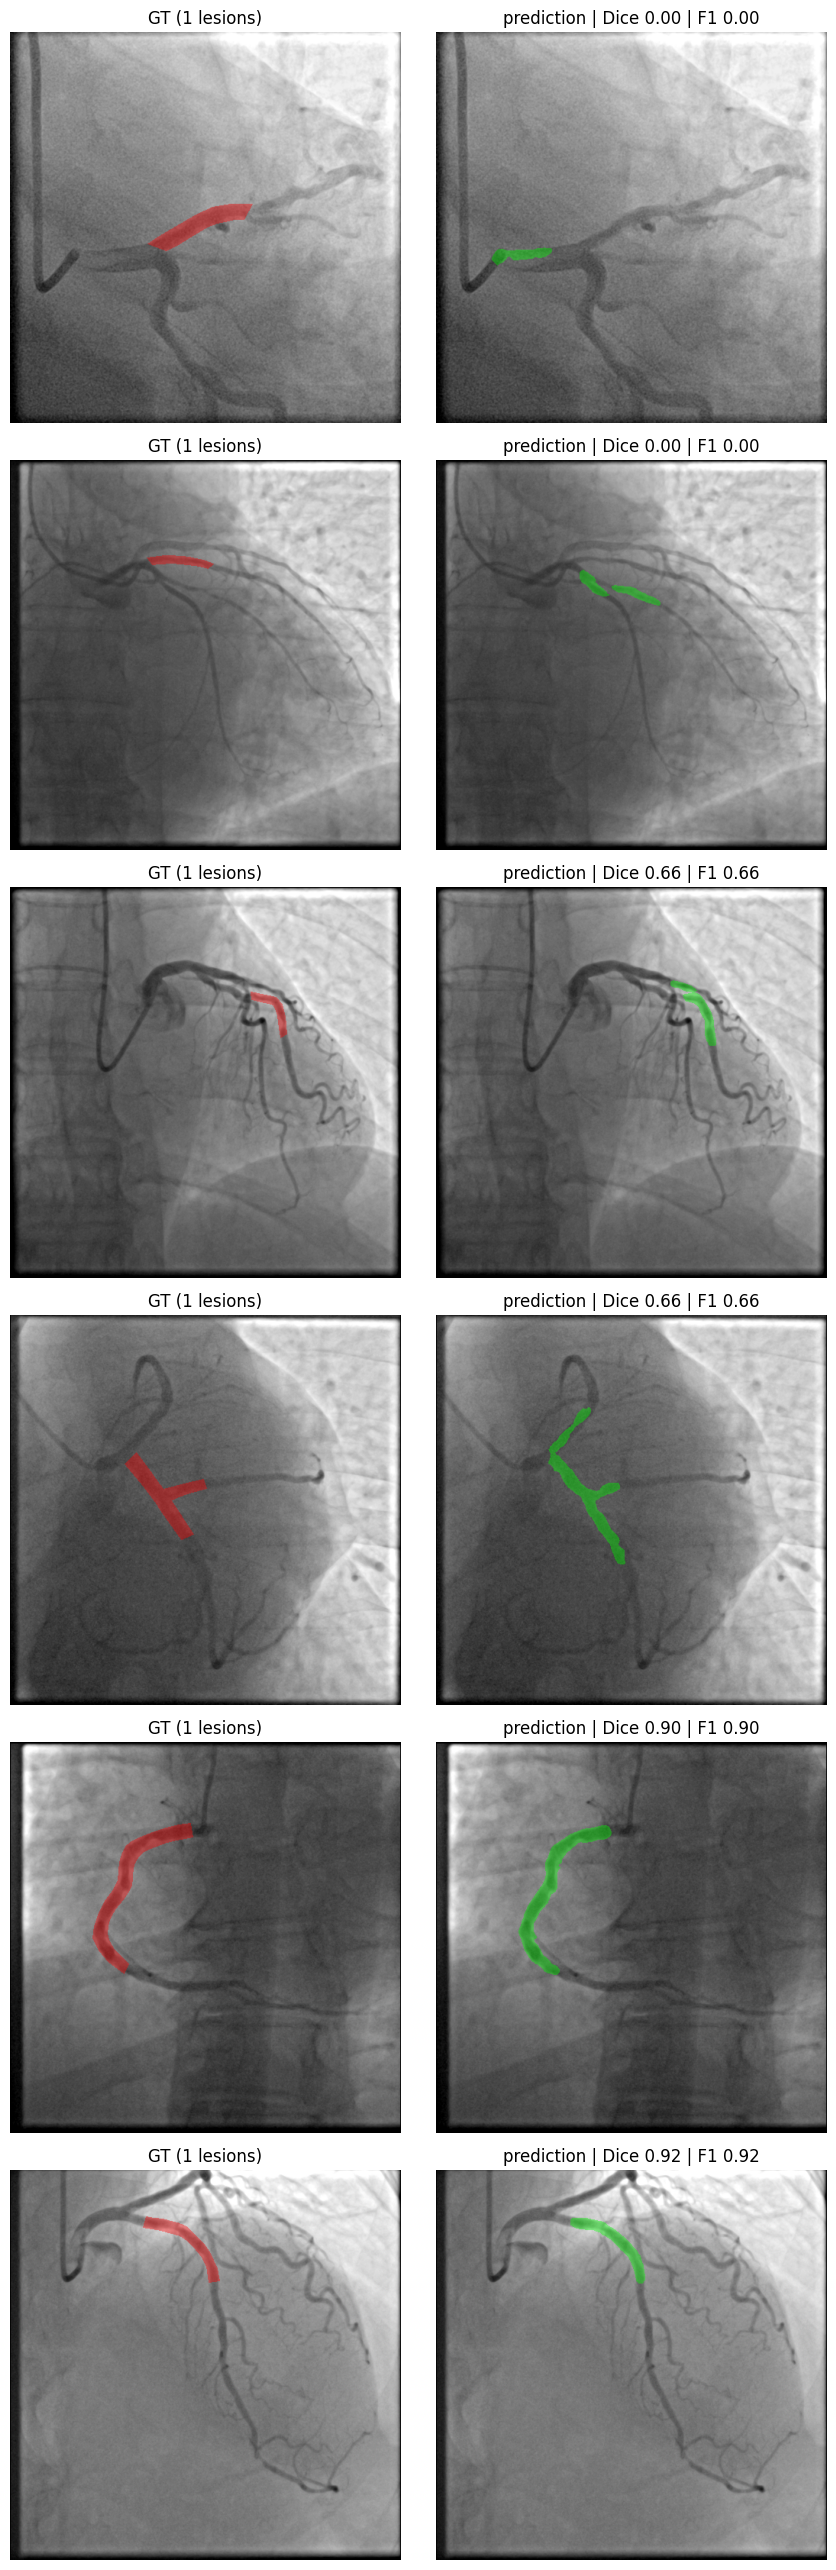

In [15]:
# ---- qualitative check: GT (red) vs ensemble prediction (green) at 'balanced-ARCADE' ----
cfg = OPS["balanced-ARCADE"]; fm, C = eval_op(ENS, cfg)
order = np.argsort(fm["per_image_Dice"]); pick = list(order[:2]) + list(order[len(order) // 2:len(order) // 2 + 2]) + list(order[-2:])
fig, ax = plt.subplots(len(pick), 2, figsize=(9, 4.3 * len(pick)))
for r_, i in enumerate(pick):
    img = cv2.cvtColor(TEST_IMGS[i], cv2.COLOR_GRAY2RGB)
    o1 = img.copy(); o1[GTU_TEST[i]] = [255, 0, 0]; ax[r_, 0].imshow(cv2.addWeighted(img, 0.6, o1, 0.4, 0)); ax[r_, 0].set_title(f"GT ({len(TEST_ITEMS[i]['gts'])} lesions)")
    pm = paint(select_insts(C[i], cfg), TEST_ITEMS[i]["shape"]); o2 = img.copy(); o2[pm] = [0, 255, 0]
    ax[r_, 1].imshow(cv2.addWeighted(img, 0.6, o2, 0.4, 0)); ax[r_, 1].set_title(f"prediction | Dice {fm['per_image_Dice'][i]:.2f} | F1 {fm['per_image_P1'][i]:.2f}")
    ax[r_, 0].axis("off"); ax[r_, 1].axis("off")
plt.tight_layout(); print("=== SS-6: worst 2 / median 2 / best 2 test images (by Dice) ==="); plt.show()

In [16]:
TAB_TEST.to_csv(OUT_DIR / "test_results_six_operating_points.csv", index=False)
GATE.to_csv(OUT_DIR / "claim_gate.csv", index=False)
DF_OOF.sort_values("p1", ascending=False).head(200).to_csv(OUT_DIR / "oof_search_top200.csv", index=False)
tta_tab.to_csv(OUT_DIR / "oof_tta_modes.csv", index=False)
pd.DataFrame(FOLD_LOG).to_csv(OUT_DIR / "fold_log.csv", index=False)
shutil.make_archive("/content/results_arcade_dl3_final", "zip", OUT_DIR)
print("Saved to", OUT_DIR)
try:
    from google.colab import files; files.download("/content/results_arcade_dl3_final.zip")
except Exception as e:
    print("Download manually: /content/results_arcade_dl3_final.zip", repr(e)[:80])
if SMOKE_TEST:
    print("\nSMOKE TEST finished: the pipeline runs end-to-end. These numbers mean nothing (1 epoch, ~120 images). Set SMOKE_TEST = False and run again.")

Saved to /content/outputs


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## How to use the result in the thesis
* Report the **test table (SS-3)** as is, with the operating-point label next to every number.
* Put the **single-model vs ensemble** line (SS-4) in the ablation: it shows what the ensemble added.
* Put the **TTA table (SS-1)** and the OOF-vs-test check in the method section: they show nothing was tuned on test.
* Be explicit about definitions: *Dice* = mean per-image Dice of the final predicted masks (pooled Dice is also given); *F1* = official ARCADE mean F1 (per-image, greedy Dice matching); the instance F1@IoU 0.5 is a different, stricter number.
* If a target is not reached, say what was reached. A transparent 0.62 with a proper protocol is worth more than an unsupported 0.65.
* The post-processing is tuned on out-of-fold predictions of *single* models, while the test prediction is the *average of 5 models* (slightly smoother probabilities). This is a mild mismatch that, if anything, works against you; mention it in the limitations.
* Ask your supervisor **which F1** the 0.55+ refers to (official ARCADE mean F1, or instance F1 at IoU 0.5). They differ a lot.